stack shape: (250, 250)


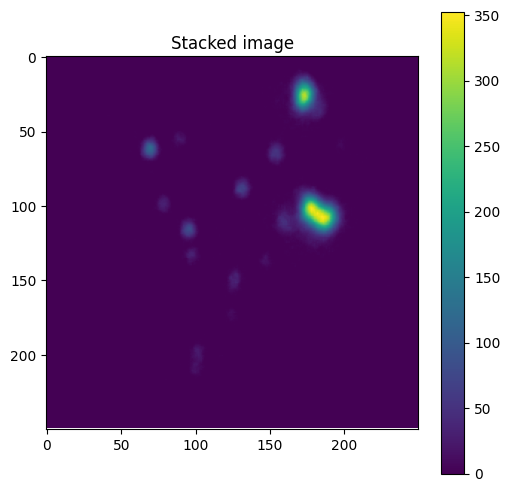

connected components: 15
peaks from peak_local_max: 17
markers after ranking: 16
watershed regions: 16


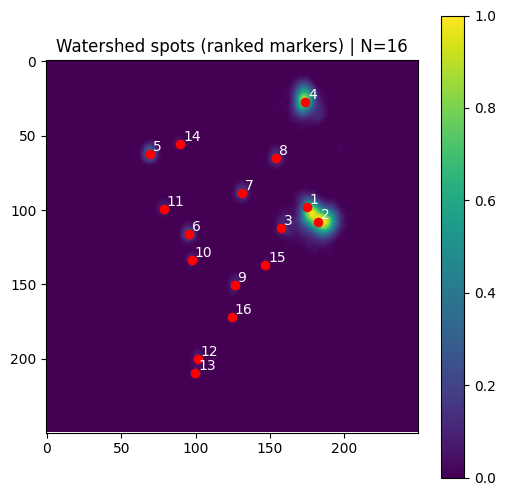

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import tifffile as tiff
from pathlib import Path

image_folder = "/Users/bananyamani/Desktop/PSI/50ms_cropped_clean"

n_images = 200   # change this whenever you want

files = sorted(Path(image_folder).glob("clean_frame_*.tif"))[:n_images]

stack = None

for f in files:
    
    img = tiff.imread(f).astype(np.float32)
    
    if stack is None:
        stack = img
    else:
        stack += img

stack /= len(files)

print("stack shape:", stack.shape)
plt.figure(figsize=(6,6))

plt.imshow(stack, )
           #cmap="gray")

plt.colorbar()
plt.ylim()
plt.title("Stacked image")

plt.show()

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

img = stack.astype(float)

threshold = 8
mask = img > threshold

cc_labels, n_cc = ndi.label(mask)
distance = ndi.distance_transform_edt(mask)

coords = peak_local_max(
    img,
    min_distance=4,
    threshold_abs=threshold,
    labels=mask
)

# --- prominence (used ONLY for ranking, not hard rejection) ---
r_in = 3
r_out = 10

def peak_prominence(image, y, x, r_in=3, r_out=10):
    y0, y1 = max(0, y - r_out), min(image.shape[0], y + r_out + 1)
    x0, x1 = max(0, x - r_out), min(image.shape[1], x + r_out + 1)
    patch = image[y0:y1, x0:x1]
    yy, xx = np.indices(patch.shape)
    cy, cx = y - y0, x - x0
    rr = np.sqrt((yy - cy)**2 + (xx - cx)**2)
    ring = patch[(rr >= r_in) & (rr <= r_out)]
    if ring.size == 0:
        return 0.0
    return float(image[y, x] - np.median(ring))

# compute prominences and group peaks by connected component
areas = np.bincount(cc_labels.ravel())
by_comp = {}

for (y, x) in coords:
    comp = int(cc_labels[y, x])
    if comp == 0:
        continue
    p = peak_prominence(img, y, x, r_in=r_in, r_out=r_out)
    by_comp.setdefault(comp, []).append((y, x, p, img[y, x]))

# choose how many peaks to allow per component
small_component_area_px = 250
k_small = 2   # allow 2 peaks in small blobs (resolves pairs)
k_large = 4   # allow 1 peak in large blobs (prevents over-seeding)

coords_filt = []
for comp, lst in by_comp.items():
    k = k_small if areas[comp] <= small_component_area_px else k_large
    # sort by prominence, then intensity as tie-breaker
    lst_sorted = sorted(lst, key=lambda t: (t[2], t[3]), reverse=True)
    lst_keep = lst_sorted[:k]
    coords_filt.extend([(y, x) for (y, x, p, I) in lst_keep])

coords_filt = np.array(coords_filt, dtype=int)

# markers
markers = np.zeros_like(img, dtype=int)
for k, (y, x) in enumerate(coords_filt, start=1):
    markers[y, x] = k

# watershed
ws = watershed(-distance, markers, mask=mask)

region_ids = np.unique(ws)
region_ids = region_ids[region_ids != 0]
centroids = ndi.center_of_mass(img, labels=ws, index=region_ids)

print("connected components:", n_cc)
print("peaks from peak_local_max:", len(coords))
print("markers after ranking:", len(coords_filt))
print("watershed regions:", len(region_ids))

plt.figure(figsize=(6,6))
plt.imshow(img, cmap="viridis", origin="upper")
for i, (y, x) in enumerate(centroids, start=1):
    plt.scatter(x, y, color="red", s=35)
    plt.text(x+2, y-2, str(i), color="white", fontsize=10)
plt.title(f"Watershed spots (ranked markers) | N={len(region_ids)}")
plt.colorbar()
plt.show()

frames used: 200
stack min/max: 0.0 352.79998779296875
connected components: 15
peaks detected: 17
markers after ranking: 14
final watershed regions: 14
4-8: dx=2.03, dy=16.98, d=17.10
7-14: dx=-1.79, dy=21.84, d=21.92


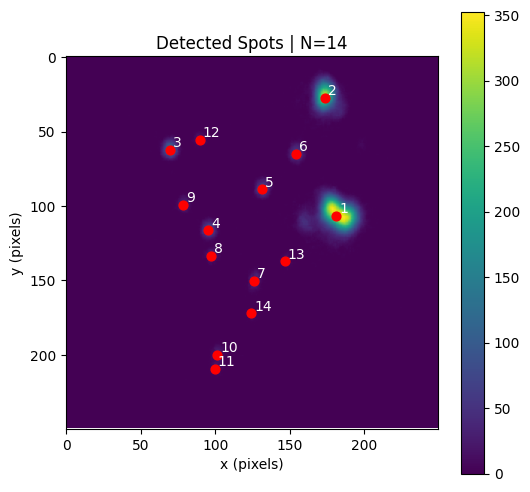

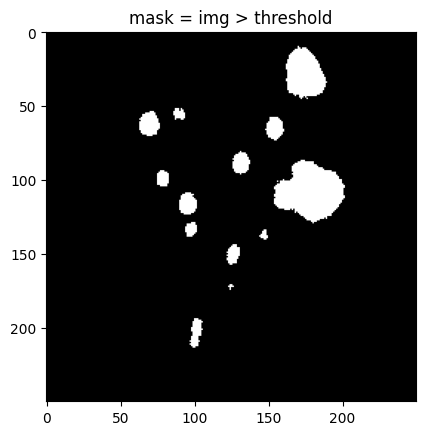

In [ ]:
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import ndimage as ndi
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

image_folder = "/Users/bananyamani/Desktop/PSI/50ms_cropped_clean"
n_images = 200
threshold = 8

files = sorted(Path(image_folder).glob("clean_frame_*.tif"))[:n_images]
if len(files) == 0:
    raise RuntimeError("No files found matching clean_frame_*.tif")

stack = None

for f in files:
    frame = tiff.imread(f).astype(np.float32)
    if stack is None:
        stack = frame.copy()
    else:
        stack += frame

stack /= float(len(files))
img = stack.astype(np.float32)

img_min = float(img.min())
img_max = float(img.max())

print("frames used:", len(files))
print("stack min/max:", img_min, img_max)

# ---------------------------
# DETECTION
# ---------------------------
mask = img > threshold
cc_labels, n_cc = ndi.label(mask)
distance = ndi.distance_transform_edt(mask)

coords = peak_local_max(
    img,
    min_distance=4,
    threshold_abs=threshold,
    labels=mask
)

r_in = 3
r_out = 10

def peak_prominence(image, y, x, r_in=3, r_out=10):
    y0, y1 = max(0, y - r_out), min(image.shape[0], y + r_out + 1)
    x0, x1 = max(0, x - r_out), min(image.shape[1], x + r_out + 1)
    patch = image[y0:y1, x0:x1]
    yy, xx = np.indices(patch.shape)
    cy, cx = y - y0, x - x0
    rr = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
    ring = patch[(rr >= r_in) & (rr <= r_out)]
    if ring.size == 0:
        return 0.0
    return float(image[y, x] - np.median(ring))

areas = np.bincount(cc_labels.ravel())
by_comp = {}

for (y, x) in coords:
    comp = int(cc_labels[y, x])
    if comp == 0:
        continue
    p = peak_prominence(img, int(y), int(x), r_in=r_in, r_out=r_out)
    by_comp.setdefault(comp, []).append((int(y), int(x), p, float(img[y, x])))

small_component_area_px = 250
k_small = 2
k_large = 1

coords_filt = []
for comp, lst in by_comp.items():
    k = k_small if areas[comp] <= small_component_area_px else k_large
    lst_sorted = sorted(lst, key=lambda t: (t[2], t[3]), reverse=True)
    coords_filt.extend([(y, x) for (y, x, p, I) in lst_sorted[:k]])

coords_filt = np.array(coords_filt, dtype=np.int32)  # IMPORTANT: int indices

# ---------------------------
# WATERSHED
# ---------------------------
markers = np.zeros_like(img, dtype=np.int32)
for k, (y, x) in enumerate(coords_filt, start=1):
    markers[y, x] = k

ws = watershed(-distance, markers, mask=mask)

region_ids = np.unique(ws)
region_ids = region_ids[region_ids != 0]
centroids = ndi.center_of_mass(img, labels=ws, index=region_ids)

print("connected components:", n_cc)
print("peaks detected:", len(coords))
print("markers after ranking:", len(coords_filt))
print("final watershed regions:", len(region_ids))

pairs = [(4, 8), (7, 14)]

def spot_delta(centroids, i, j):
    """
    Compute dx, dy and Euclidean distance between two detected spots.

    Parameters
    ----------
    centroids : list or array
        Output from ndi.center_of_mass()
    i : int
        first spot number (1-based indexing)
    j : int
        second spot number (1-based indexing)

    Returns
    -------
    dx : float
        x displacement (pixels)
    dy : float
        y displacement (pixels)
    d : float
        Euclidean distance (pixels)
    """

    y1, x1 = centroids[i - 1]
    y2, x2 = centroids[j - 1]

    dx = x2 - x1
    dy = y2 - y1

    d = np.sqrt(dx**2 + dy**2)

    return dx, dy, d

for i, j in pairs:
    dx, dy, d = spot_delta(centroids, i, j)
    print(f"{i}-{j}: dx={dx:.2f}, dy={dy:.2f}, d={d:.2f}")

# ---------------------------
# SAVE STACKED IMAGE (NO SPOTS)
# ---------------------------
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(
    img,
    cmap="viridis",
    origin="upper",
    vmin=img_min,
    vmax=img_max
)
fig.colorbar(im, ax=ax)
ax.set_title("Average Stacked Image")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")
fig.savefig("stacked_image.png", dpi=300, bbox_inches="tight")
plt.close(fig)

# ---------------------------
# SAVE STACKED IMAGE (WITH SPOTS)
# ---------------------------
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(
    img,
    cmap="viridis",
    origin="upper",
    vmin=img_min,
    vmax=img_max
)

for i, (y, x) in enumerate(centroids, start=1):
    ax.scatter(x, y, color="red", s=40)
    ax.text(x + 2, y - 2, str(i), color="white", fontsize=10)

fig.colorbar(im, ax=ax)
ax.set_title(f"Detected Spots | N={len(region_ids)}")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")

fig.savefig("stacked_image_with_spots.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure()
plt.imshow(mask, cmap="gray", origin="upper")
plt.title("mask = img > threshold")
plt.show()

1-Gaussian RSS: 7210.5809508780085
2-Gaussian RSS: 4072.899298153755
1-Gaussian BIC: 2602.8091987019097
2-Gaussian BIC: 1490.823969249028
2-Gaussian fit is preferred

1-Gaussian center:
x = 126.21, y = 150.16

2-Gaussian centers:
spot A: x = 126.61, y = 148.01
spot B: x = 125.63, y = 153.35


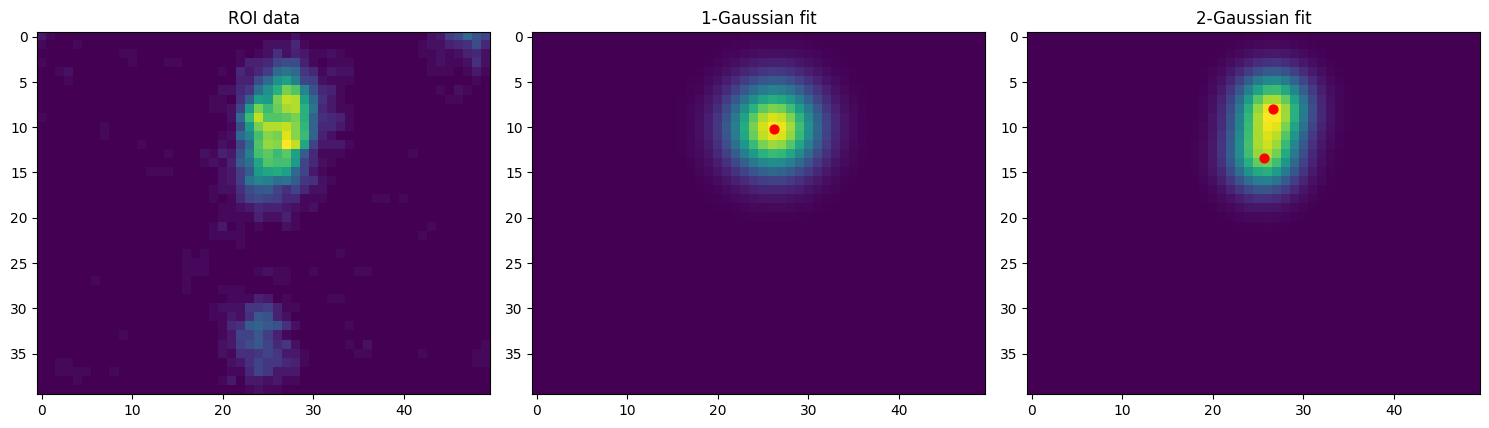

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# -----------------------------
# ROI from your stacked image
# -----------------------------
x1, x2 = 100, 150
y1, y2 = 140, 180

roi = img[y1:y2, x1:x2].astype(float)

# local pixel coordinates inside ROI
yy, xx = np.indices(roi.shape)

# flatten for fitting
xdata = xx.ravel()
ydata = yy.ravel()
zdata = roi.ravel()

# -----------------------------
# Models
# -----------------------------
def gauss2d_1(coords, A1, x01, y01, s1, B):
    x, y = coords
    g1 = A1 * np.exp(-((x - x01)**2 + (y - y01)**2) / (2 * s1**2))
    return (g1 + B).ravel()

def gauss2d_2(coords, A1, x01, y01, s1, A2, x02, y02, s2, B):
    x, y = coords
    g1 = A1 * np.exp(-((x - x01)**2 + (y - y01)**2) / (2 * s1**2))
    g2 = A2 * np.exp(-((x - x02)**2 + (y - y02)**2) / (2 * s2**2))
    return (g1 + g2 + B).ravel()

# -----------------------------
# Initial guesses
# -----------------------------
B0 = np.median(roi)
A0 = roi.max() - B0

# brightest point in ROI
iy, ix = np.unravel_index(np.argmax(roi), roi.shape)

# 1-spot initial guess
p0_1 = [A0, ix, iy, 2.5, B0]

# 2-spot initial guess
# second spot guessed 1 px below
p0_2 = [0.7*A0, ix, iy-1, 2.5,
        0.5*A0, ix, iy+1, 2.5,
        B0]

# -----------------------------
# Fit 1 Gaussian
# -----------------------------
bounds_1 = (
    [0,    0,    0,    0.5, 0],
    [1e6, roi.shape[1], roi.shape[0], 10,  1e6]
)

popt1, _ = curve_fit(
    gauss2d_1,
    (xdata, ydata),
    zdata,
    p0=p0_1,
    bounds=bounds_1,
    maxfev=20000
)

fit1 = gauss2d_1((xx, yy), *popt1).reshape(roi.shape)
rss1 = np.sum((roi - fit1)**2)

# -----------------------------
# Fit 2 Gaussians
# -----------------------------
bounds_2 = (
    [0,    0,    0,    0.5,  0,    0,    0,    0.5, 0],
    [1e6, roi.shape[1], roi.shape[0], 10, 1e6, roi.shape[1], roi.shape[0], 10, 1e6]
)

popt2, _ = curve_fit(
    gauss2d_2,
    (xdata, ydata),
    zdata,
    p0=p0_2,
    bounds=bounds_2,
    maxfev=40000
)

fit2 = gauss2d_2((xx, yy), *popt2).reshape(roi.shape)
rss2 = np.sum((roi - fit2)**2)

# -----------------------------
# BIC comparison
# -----------------------------
n = roi.size
k1 = 5
k2 = 9

bic1 = n * np.log(rss1 / n) + k1 * np.log(n)
bic2 = n * np.log(rss2 / n) + k2 * np.log(n)

print("1-Gaussian RSS:", rss1)
print("2-Gaussian RSS:", rss2)
print("1-Gaussian BIC:", bic1)
print("2-Gaussian BIC:", bic2)

if bic2 < bic1:
    print("2-Gaussian fit is preferred")
else:
    print("1-Gaussian fit is preferred")

# -----------------------------
# Convert fitted centers to full-image coordinates
# -----------------------------
x01_full = x1 + popt1[1]
y01_full = y1 + popt1[2]

x021_full = x1 + popt2[1]
y021_full = y1 + popt2[2]

x022_full = x1 + popt2[5]
y022_full = y1 + popt2[6]

print("\n1-Gaussian center:")
print(f"x = {x01_full:.2f}, y = {y01_full:.2f}")

print("\n2-Gaussian centers:")
print(f"spot A: x = {x021_full:.2f}, y = {y021_full:.2f}")
print(f"spot B: x = {x022_full:.2f}, y = {y022_full:.2f}")

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(roi, cmap="viridis", origin="upper")
ax[0].set_title("ROI data")

ax[1].imshow(fit1, cmap="viridis", origin="upper")
ax[1].scatter([popt1[1]], [popt1[2]], c="red", s=40)
ax[1].set_title("1-Gaussian fit")

ax[2].imshow(fit2, cmap="viridis", origin="upper")
ax[2].scatter([popt2[1], popt2[5]], [popt2[2], popt2[6]], c="red", s=40)
ax[2].set_title("2-Gaussian fit")

plt.tight_layout()
plt.show()

frames used: 200
stack min/max: 0.0 352.79998779296875
connected components: 15
peaks detected: 17
markers after ranking: 14
final watershed regions: 14
4-8: dx=2.03, dy=16.98, d=17.10
7-14: dx=-1.79, dy=21.84, d=21.92

ROI: (100, 150, 140, 180)
1-Gaussian RSS: 7210.5809508780085
2-Gaussian RSS: 4072.899298153755
1-Gaussian BIC: 2602.8091987019097
2-Gaussian BIC: 1490.823969249028
2-Gaussian fit is preferred

1-Gaussian center:
x = 126.21, y = 150.16

2-Gaussian centers:
spot A: x = 126.61, y = 148.01
spot B: x = 125.63, y = 153.35
dx = -0.97, dy = 5.35, d = 5.43 pixels


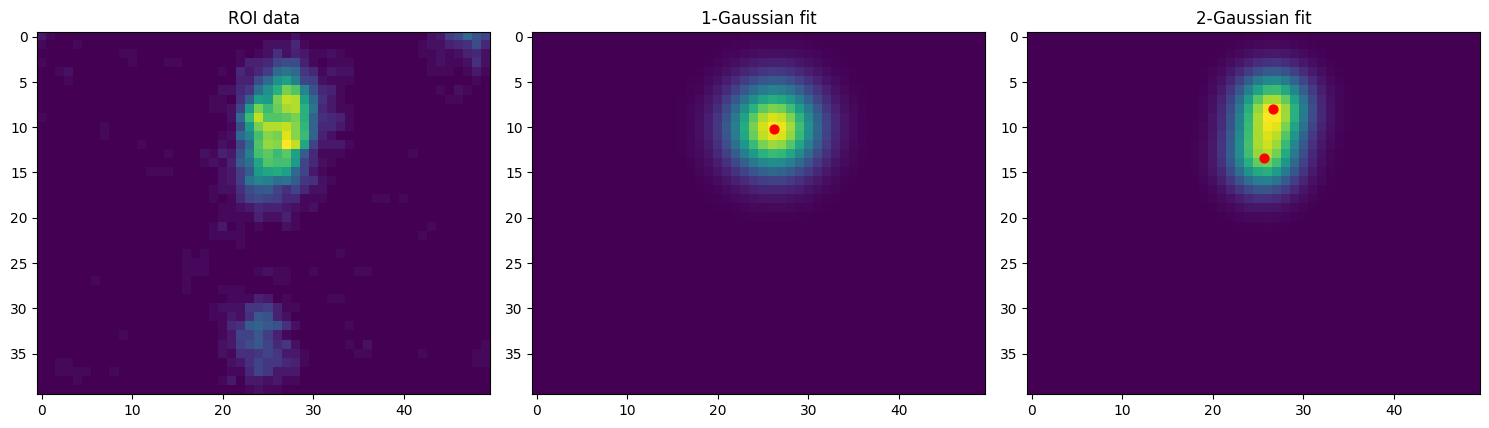

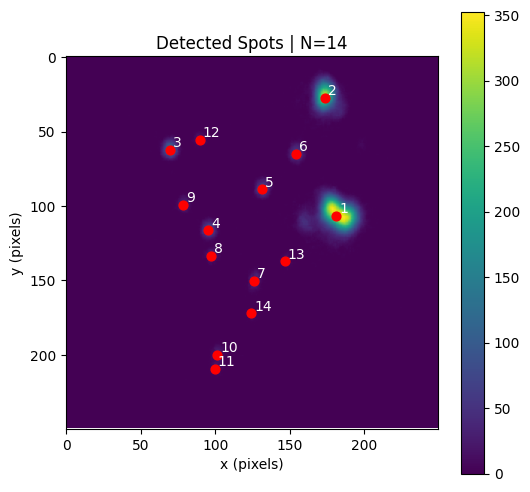

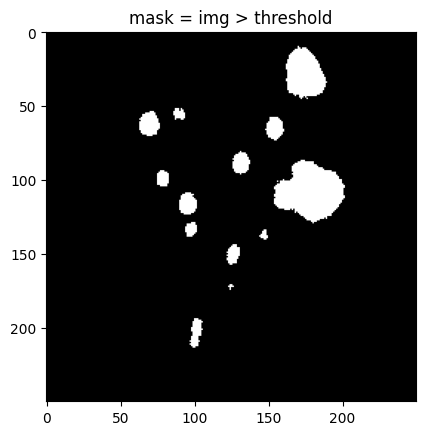

In [5]:
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import ndimage as ndi
from scipy.optimize import curve_fit
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

image_folder = "/Users/bananyamani/Desktop/PSI/50ms_cropped_clean"
n_images = 200
threshold = 8

files = sorted(Path(image_folder).glob("clean_frame_*.tif"))[:n_images]
if len(files) == 0:
    raise RuntimeError("No files found matching clean_frame_*.tif")

stack = None

for f in files:
    frame = tiff.imread(f).astype(np.float32)
    if stack is None:
        stack = frame.copy()
    else:
        stack += frame

stack /= float(len(files))
img = stack.astype(np.float32)

img_min = float(img.min())
img_max = float(img.max())

print("frames used:", len(files))
print("stack min/max:", img_min, img_max)

# ---------------------------
# DETECTION
# ---------------------------
mask = img > threshold
cc_labels, n_cc = ndi.label(mask)
distance = ndi.distance_transform_edt(mask)

coords = peak_local_max(
    img,
    min_distance=4,
    threshold_abs=threshold,
    labels=mask
)

r_in = 3
r_out = 10

def peak_prominence(image, y, x, r_in=3, r_out=10):
    y0, y1 = max(0, y - r_out), min(image.shape[0], y + r_out + 1)
    x0, x1 = max(0, x - r_out), min(image.shape[1], x + r_out + 1)
    patch = image[y0:y1, x0:x1]
    yy, xx = np.indices(patch.shape)
    cy, cx = y - y0, x - x0
    rr = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
    ring = patch[(rr >= r_in) & (rr <= r_out)]
    if ring.size == 0:
        return 0.0
    return float(image[y, x] - np.median(ring))

areas = np.bincount(cc_labels.ravel())
by_comp = {}

for (y, x) in coords:
    comp = int(cc_labels[y, x])
    if comp == 0:
        continue
    p = peak_prominence(img, int(y), int(x), r_in=r_in, r_out=r_out)
    by_comp.setdefault(comp, []).append((int(y), int(x), p, float(img[y, x])))

small_component_area_px = 250
k_small = 2
k_large = 1

coords_filt = []
for comp, lst in by_comp.items():
    k = k_small if areas[comp] <= small_component_area_px else k_large
    lst_sorted = sorted(lst, key=lambda t: (t[2], t[3]), reverse=True)
    coords_filt.extend([(y, x) for (y, x, p, I) in lst_sorted[:k]])

coords_filt = np.array(coords_filt, dtype=np.int32)

# ---------------------------
# WATERSHED
# ---------------------------
markers = np.zeros_like(img, dtype=np.int32)
for k, (y, x) in enumerate(coords_filt, start=1):
    markers[y, x] = k

ws = watershed(-distance, markers, mask=mask)

region_ids = np.unique(ws)
region_ids = region_ids[region_ids != 0]
centroids = ndi.center_of_mass(img, labels=ws, index=region_ids)

print("connected components:", n_cc)
print("peaks detected:", len(coords))
print("markers after ranking:", len(coords_filt))
print("final watershed regions:", len(region_ids))

pairs = [(4, 8), (7, 14)]

def spot_delta(centroids, i, j):
    y1, x1 = centroids[i - 1]
    y2, x2 = centroids[j - 1]
    dx = x2 - x1
    dy = y2 - y1
    d = np.sqrt(dx**2 + dy**2)
    return dx, dy, d

for i, j in pairs:
    dx, dy, d = spot_delta(centroids, i, j)
    print(f"{i}-{j}: dx={dx:.2f}, dy={dy:.2f}, d={d:.2f}")

# ---------------------------
# 1-vs-2 GAUSSIAN ROI FIT
# ---------------------------
def fit_roi_as_one_or_two_gaussians(img, x1, x2, y1, y2, plot=True):
    roi = img[y1:y2, x1:x2].astype(float)

    yy, xx = np.indices(roi.shape)
    xdata = xx.ravel()
    ydata = yy.ravel()
    zdata = roi.ravel()

    def gauss2d_1(coords, A1, x01, y01, s1, B):
        x, y = coords
        g1 = A1 * np.exp(-((x - x01)**2 + (y - y01)**2) / (2 * s1**2))
        return (g1 + B).ravel()

    def gauss2d_2(coords, A1, x01, y01, s1, A2, x02, y02, s2, B):
        x, y = coords
        g1 = A1 * np.exp(-((x - x01)**2 + (y - y01)**2) / (2 * s1**2))
        g2 = A2 * np.exp(-((x - x02)**2 + (y - y02)**2) / (2 * s2**2))
        return (g1 + g2 + B).ravel()

    B0 = np.median(roi)
    A0 = roi.max() - B0
    iy, ix = np.unravel_index(np.argmax(roi), roi.shape)

    p0_1 = [A0, ix, iy, 2.5, B0]
    p0_2 = [0.7*A0, ix, iy-1, 2.5,
            0.5*A0, ix, iy+1, 2.5,
            B0]

    bounds_1 = (
        [0, 0, 0, 0.5, 0],
        [1e6, roi.shape[1], roi.shape[0], 10, 1e6]
    )

    bounds_2 = (
        [0, 0, 0, 0.5, 0, 0, 0, 0.5, 0],
        [1e6, roi.shape[1], roi.shape[0], 10,
         1e6, roi.shape[1], roi.shape[0], 10, 1e6]
    )

    popt1, _ = curve_fit(
        gauss2d_1, (xdata, ydata), zdata,
        p0=p0_1, bounds=bounds_1, maxfev=20000
    )
    fit1 = gauss2d_1((xx, yy), *popt1).reshape(roi.shape)
    rss1 = np.sum((roi - fit1)**2)

    popt2, _ = curve_fit(
        gauss2d_2, (xdata, ydata), zdata,
        p0=p0_2, bounds=bounds_2, maxfev=40000
    )
    fit2 = gauss2d_2((xx, yy), *popt2).reshape(roi.shape)
    rss2 = np.sum((roi - fit2)**2)

    n = roi.size
    k1 = 5
    k2 = 9

    bic1 = n * np.log(rss1 / n) + k1 * np.log(n)
    bic2 = n * np.log(rss2 / n) + k2 * np.log(n)

    x01_full = x1 + popt1[1]
    y01_full = y1 + popt1[2]

    xA = x1 + popt2[1]
    yA = y1 + popt2[2]

    xB = x1 + popt2[5]
    yB = y1 + popt2[6]

    dx = xB - xA
    dy = yB - yA
    d_px = np.sqrt(dx**2 + dy**2)

    print("\nROI:", (x1, x2, y1, y2))
    print("1-Gaussian RSS:", rss1)
    print("2-Gaussian RSS:", rss2)
    print("1-Gaussian BIC:", bic1)
    print("2-Gaussian BIC:", bic2)

    if bic2 < bic1:
        print("2-Gaussian fit is preferred")
    else:
        print("1-Gaussian fit is preferred")

    print("\n1-Gaussian center:")
    print(f"x = {x01_full:.2f}, y = {y01_full:.2f}")

    print("\n2-Gaussian centers:")
    print(f"spot A: x = {xA:.2f}, y = {yA:.2f}")
    print(f"spot B: x = {xB:.2f}, y = {yB:.2f}")
    print(f"dx = {dx:.2f}, dy = {dy:.2f}, d = {d_px:.2f} pixels")

    if plot:
        fig, ax = plt.subplots(1, 3, figsize=(15, 5))

        ax[0].imshow(roi, cmap="viridis", origin="upper")
        ax[0].set_title("ROI data")

        ax[1].imshow(fit1, cmap="viridis", origin="upper")
        ax[1].scatter([popt1[1]], [popt1[2]], c="red", s=40)
        ax[1].set_title("1-Gaussian fit")

        ax[2].imshow(fit2, cmap="viridis", origin="upper")
        ax[2].scatter([popt2[1], popt2[5]], [popt2[2], popt2[6]], c="red", s=40)
        ax[2].set_title("2-Gaussian fit")

        plt.tight_layout()
        plt.show()

    return {
        "rss1": rss1,
        "rss2": rss2,
        "bic1": bic1,
        "bic2": bic2,
        "preferred_model": 2 if bic2 < bic1 else 1,
        "one_gaussian_center": (x01_full, y01_full),
        "two_gaussian_centers": ((xA, yA), (xB, yB)),
        "dx_px": dx,
        "dy_px": dy,
        "distance_px": d_px
    }

# ---------------------------
# SET ROI HERE
# ---------------------------
roi_result = fit_roi_as_one_or_two_gaussians(
    img,
    x1=100, x2=150,
    y1=140, y2=180,
    plot=True
)

# ---------------------------
# SAVE STACKED IMAGE (NO SPOTS)
# ---------------------------
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(
    img,
    cmap="viridis",
    origin="upper",
    vmin=img_min,
    vmax=img_max
)
fig.colorbar(im, ax=ax)
ax.set_title("Average Stacked Image")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")
fig.savefig("stacked_image.png", dpi=300, bbox_inches="tight")
plt.close(fig)

# ---------------------------
# SAVE STACKED IMAGE (WITH SPOTS)
# ---------------------------
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(
    img,
    cmap="viridis",
    origin="upper",
    vmin=img_min,
    vmax=img_max
)

for i, (y, x) in enumerate(centroids, start=1):
    ax.scatter(x, y, color="red", s=40)
    ax.text(x + 2, y - 2, str(i), color="white", fontsize=10)

fig.colorbar(im, ax=ax)
ax.set_title(f"Detected Spots | N={len(region_ids)}")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")

fig.savefig("stacked_image_with_spots.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure()
plt.imshow(mask, cmap="gray", origin="upper")
plt.title("mask = img > threshold")
plt.show()


ROI: (125, 160, 85, 150)
1-Gaussian RSS: 83332.20142008761
2-Gaussian RSS: 82202.1457915472
1-Gaussian BIC: 8230.593787415482
2-Gaussian BIC: 8230.450697965149
2-Gaussian fit is preferred

1-Gaussian center:
x = 131.12, y = 89.05

2-Gaussian centers:
spot A: x = 131.72, y = 85.31
spot B: x = 130.98, y = 89.84
dx = -0.74, dy = 4.52, d = 4.58 pixels


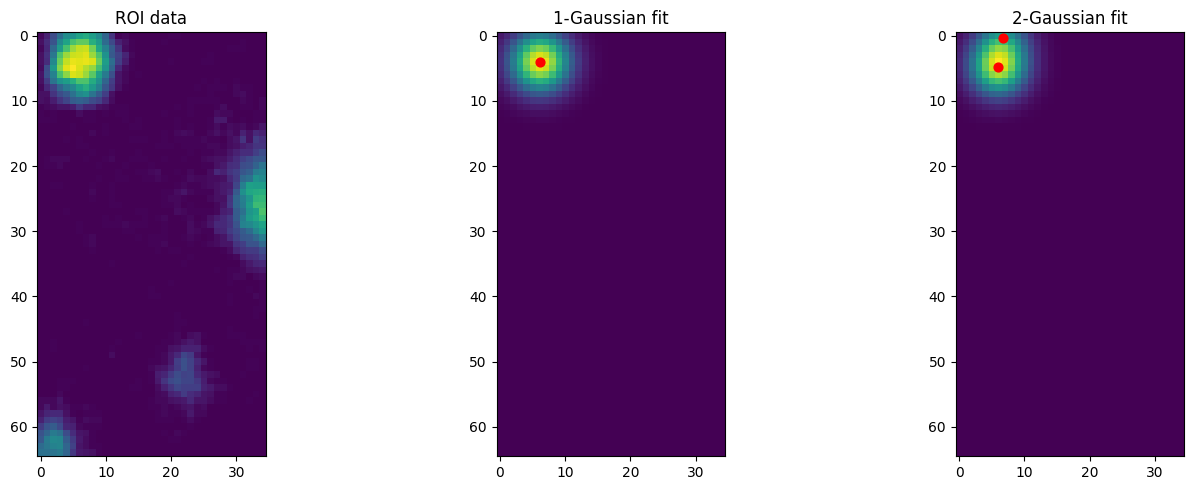

In [6]:
roi_result_714 = fit_roi_as_one_or_two_gaussians(
    img,
    x1=125, x2=160,
    y1=85, y2=150,
    plot=True
)

frames used: 200
stack min/max: 0.0 352.79998779296875
connected components found: 15
components successfully fit: 13
final spots after 1-vs-2 Gaussian fitting: 19
15-16: dx=-0.98, dy=5.39, d=5.48
18-19: dx=-1.24, dy=9.60, d=9.68


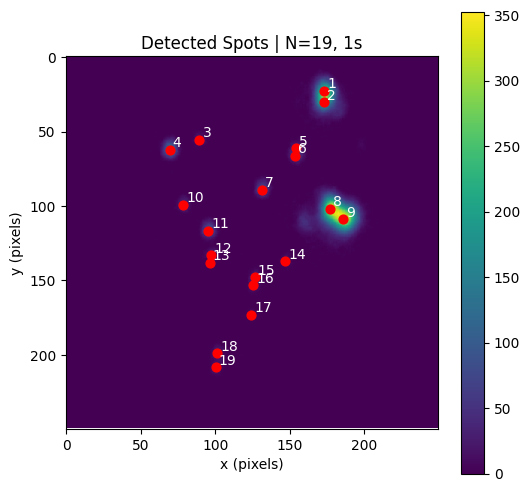

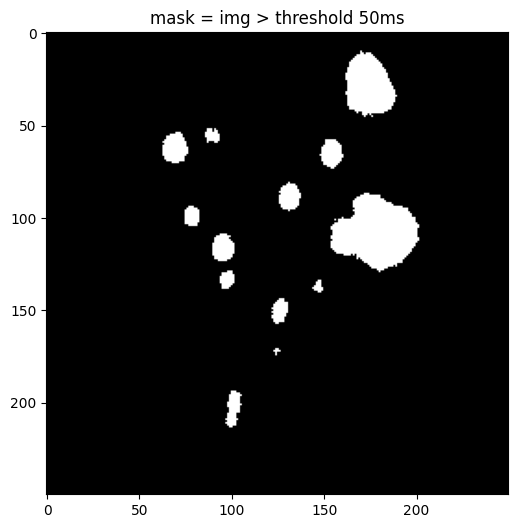

comp  1 | area= 700 | model=2 | bic1=8620.60 | bic2=6464.19 | sep=7.52
comp  3 | area=  49 | model=1 | bic1=222.98 | bic2=176.25 | sep=3.24
comp  4 | area= 183 | model=1 | bic1=1804.08 | bic2=1148.20 | sep=4.56
comp  5 | area= 146 | model=2 | bic1=1156.09 | bic2=808.08 | sep=5.03
comp  6 | area= 139 | model=1 | bic1=1178.00 | bic2=923.61 | sep=4.56
comp  7 | area=1351 | model=2 | bic1=18155.57 | bic2=13571.52 | sep=11.50
comp  8 | area=  77 | model=1 | bic1=497.48 | bic2=309.09 | sep=4.02
comp 10 | area= 146 | model=1 | bic1=1140.82 | bic2=836.23 | sep=4.32
comp 11 | area=  63 | model=2 | bic1=386.41 | bic2=305.42 | sep=5.34
comp 12 | area=  25 | model=1 | bic1=218.29 | bic2=75.74 | sep=3.71
comp 13 | area=  92 | model=2 | bic1=983.09 | bic2=608.03 | sep=5.48
comp 14 | area=   8 | model=1 | bic1=99.99 | bic2=37.24 | sep=3.70
comp 15 | area= 113 | model=2 | bic1=1400.99 | bic2=831.75 | sep=9.68


In [35]:
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import ndimage as ndi
from scipy.optimize import curve_fit

# ---------------------------
# SETTINGS
# ---------------------------
image_folder = "/Users/bananyamani/Desktop/PSI/50ms_cropped_clean"
n_images = 200
threshold = 8

# component handling
min_component_area = 3       # ignore tiny junk
max_component_area = 10000   # safety
roi_pad = 4                  # pixels around each component bbox

# Gaussian model selection
bic_improvement_needed = 10  # require 2-Gaussian BIC to be lower by at least this much
min_two_spot_sep = 5      # pixels, reject fake double fits if centers nearly coincide

# ---------------------------
# LOAD + AVERAGE STACK
# ---------------------------
files = sorted(Path(image_folder).glob("clean_frame_*.tif"))[:n_images]
if len(files) == 0:
    raise RuntimeError("No files found matching clean_frame_*.tif")

stack = None
for f in files:
    frame = tiff.imread(f).astype(np.float32)
    if stack is None:
        stack = frame.copy()
    else:
        stack += frame

stack /= float(len(files))
img = stack.astype(np.float32)

img_min = float(img.min())
img_max = float(img.max())

print("frames used:", len(files))
print("stack min/max:", img_min, img_max)

# ---------------------------
# THRESHOLD + CONNECTED COMPONENTS
# ---------------------------
mask = img > threshold
cc_labels, n_cc = ndi.label(mask)

print("connected components found:", n_cc)

# component sizes
areas = np.bincount(cc_labels.ravel())

# ---------------------------
# GAUSSIAN FIT HELPERS
# ---------------------------
def gauss2d_1(coords, A1, x01, y01, s1, B):
    x, y = coords
    g1 = A1 * np.exp(-((x - x01)**2 + (y - y01)**2) / (2 * s1**2))
    return (g1 + B).ravel()

def gauss2d_2(coords, A1, x01, y01, s1, A2, x02, y02, s2, B):
    x, y = coords
    g1 = A1 * np.exp(-((x - x01)**2 + (y - y01)**2) / (2 * s1**2))
    g2 = A2 * np.exp(-((x - x02)**2 + (y - y02)**2) / (2 * s2**2))
    return (g1 + g2 + B).ravel()

def bic_from_rss(rss, n, k):
    rss = max(rss, 1e-12)
    return n * np.log(rss / n) + k * np.log(n)

def fit_component_roi(img, x1, x2, y1, y2):
    roi = img[y1:y2, x1:x2].astype(float)

    yy, xx = np.indices(roi.shape)
    xdata = xx.ravel()
    ydata = yy.ravel()
    zdata = roi.ravel()

    B0 = float(np.median(roi))
    A0 = float(roi.max() - B0)

    iy, ix = np.unravel_index(np.argmax(roi), roi.shape)

    # 1-Gaussian init
    p0_1 = [A0, ix, iy, 2.5, B0]
    bounds_1 = (
        [0, 0, 0, 0.5, 0],
        [1e6, roi.shape[1], roi.shape[0], 10, 1e6]
    )

    popt1, _ = curve_fit(
        gauss2d_1, (xdata, ydata), zdata,
        p0=p0_1, bounds=bounds_1, maxfev=20000
    )
    fit1 = gauss2d_1((xx, yy), *popt1).reshape(roi.shape)
    rss1 = float(np.sum((roi - fit1)**2))
    bic1 = bic_from_rss(rss1, roi.size, 5)

    # 2-Gaussian init
    p0_2 = [0.7*A0, ix, max(0, iy-1), 2.5,
            0.5*A0, ix, min(roi.shape[0]-1, iy+1), 2.5,
            B0]
    bounds_2 = (
        [0, 0, 0, 0.5, 0, 0, 0, 0.5, 0],
        [1e6, roi.shape[1], roi.shape[0], 10,
         1e6, roi.shape[1], roi.shape[0], 10, 1e6]
    )

    popt2, _ = curve_fit(
        gauss2d_2, (xdata, ydata), zdata,
        p0=p0_2, bounds=bounds_2, maxfev=40000
    )
    fit2 = gauss2d_2((xx, yy), *popt2).reshape(roi.shape)
    rss2 = float(np.sum((roi - fit2)**2))
    bic2 = bic_from_rss(rss2, roi.size, 9)

    x1g = x1 + popt1[1]
    y1g = y1 + popt1[2]

    xA = x1 + popt2[1]
    yA = y1 + popt2[2]
    xB = x1 + popt2[5]
    yB = y1 + popt2[6]

    dx = xB - xA
    dy = yB - yA
    sep = float(np.sqrt(dx**2 + dy**2))

    prefer_two = (bic2 < bic1 - bic_improvement_needed) and (sep >= min_two_spot_sep)

    if prefer_two:
        return {
            "model": 2,
            "centers": [(yA, xA), (yB, xB)],
            "bic1": bic1,
            "bic2": bic2,
            "rss1": rss1,
            "rss2": rss2,
            "sep": sep,
            "roi": (x1, x2, y1, y2)
        }
    else:
        return {
            "model": 1,
            "centers": [(y1g, x1g)],
            "bic1": bic1,
            "bic2": bic2,
            "rss1": rss1,
            "rss2": rss2,
            "sep": sep,
            "roi": (x1, x2, y1, y2)
        }

# ---------------------------
# FIT EACH CONNECTED COMPONENT
# ---------------------------
results = []
final_centroids = []

objects = ndi.find_objects(cc_labels)

for comp_id, slc in enumerate(objects, start=1):
    if slc is None:
        continue

    area = areas[comp_id]
    if area < min_component_area or area > max_component_area:
        continue

    ys, xs = slc
    y1 = max(0, ys.start - roi_pad)
    y2 = min(img.shape[0], ys.stop + roi_pad)
    x1 = max(0, xs.start - roi_pad)
    x2 = min(img.shape[1], xs.stop + roi_pad)

    try:
        fit_result = fit_component_roi(img, x1, x2, y1, y2)
        fit_result["component_id"] = comp_id
        fit_result["area"] = int(area)
        results.append(fit_result)
        final_centroids.extend(fit_result["centers"])
    except Exception as e:
        print(f"component {comp_id} fit failed:", e)

print("components successfully fit:", len(results))
print("final spots after 1-vs-2 Gaussian fitting:", len(final_centroids))

# ---------------------------
# OPTIONAL: DISTANCE HELPER
# ---------------------------
def spot_delta(centroids, i, j):
    y1, x1 = centroids[i - 1]
    y2, x2 = centroids[j - 1]
    dx = x2 - x1
    dy = y2 - y1
    d = np.sqrt(dx**2 + dy**2)
    return dx, dy, d

# example
pairs = [(15, 16), (18, 19)]
for i, j in pairs:
    dx, dy, d = spot_delta(final_centroids, i, j)
    print(f"{i}-{j}: dx={dx:.2f}, dy={dy:.2f}, d={d:.2f}")

# ---------------------------
# SAVE STACKED IMAGE (NO SPOTS)
# ---------------------------
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(
    img,
    cmap="viridis",
    origin="upper",
    vmin=img_min,
    vmax=img_max
)
fig.colorbar(im, ax=ax)
ax.set_title("Average Stacked Image")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")
fig.savefig("stacked_image.png", dpi=300, bbox_inches="tight")
plt.close(fig)

# ---------------------------
# SAVE STACKED IMAGE WITH FINAL SPOTS
# ---------------------------
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(
    img,
    cmap="viridis",
    origin="upper",
    vmin=img_min,
    vmax=img_max
)

for i, (y, x) in enumerate(final_centroids, start=1):
    ax.scatter(x, y, color="red", s=40)
    ax.text(x + 2, y - 2, str(i), color="white", fontsize=10)

fig.colorbar(im, ax=ax)
ax.set_title(f"Detected Spots | N={len(final_centroids)}, 1s")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")
fig.savefig("stacked_image_with_spots.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------
# SHOW MASK
# ---------------------------
plt.figure(figsize=(6, 6))
plt.imshow(mask, cmap="gray", origin="upper")
plt.title("mask = img > threshold 50ms")
plt.show()


for r in results:
    print(
        f"comp {r['component_id']:2d} | area={r['area']:4d} | "
        f"model={r['model']} | bic1={r['bic1']:.2f} | bic2={r['bic2']:.2f} | sep={r['sep']:.2f}"
    )